In [1]:
import json
import os
import platform
import subprocess
import sys
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

sys.path.insert(0, str(Path.cwd()))
import sweep_2
from sweep_2 import (PLAIN, SETTINGS, START, baseline, config_hash, frozen_config, greedy_flight, job_id, load_q,
                     load_results, make_env, run_jobs, stage_distance_table, summarize)

def git(*args):
    return subprocess.run(["git", *args], capture_output=True, text=True, check=True).stdout.strip()

COMMIT = git("rev-parse", "HEAD")
DIRTY = [line for line in git("status", "--porcelain", "--", "*.py").splitlines()]
print(f"commit      {COMMIT}  ({git('rev-parse', '--abbrev-ref', 'HEAD')})")
print(f"uncommitted .py changes: {DIRTY or 'none'}")
print(f"config hash {config_hash()}")

commit      d92d2100ef617130dea2ecd228c1f2c14552aa25  (stl-kinematics)
uncommitted .py changes: none
config hash 30dfb45213


## Setup

Same stack as `kinematics_agents.ipynb` (see its section *Environment for a Q-table* for the wrappers and the observation bins), wrapped in `STLKinematicMonitor`. With `w = 0` it adds no reward and with `label = False` the last

In [2]:
OUT = Path.cwd()
RESULTS = OUT / "results_kinematics.jsonl"
JOBS_FILE = OUT / "baseline_jobs.json"
META_FILE = OUT / "baseline_meta.json"
SUMMARY_CSV = OUT / "baseline_summary.csv"
Q_DIR = OUT / "q_tables"
WORKERS = 5

jobs = baseline()
JOBS_FILE.write_text(json.dumps(jobs, indent=1))

env = make_env(jobs[0])
print(f"{len(jobs)} jobs -> {RESULTS.name}")
for j in jobs:
    print("  ", job_id(j))
print(f"observation space {env.observation_space.nvec}, {env.action_space.n} actions, "
      f"w = {env.w}, observe_label = {env.observe_label}")
print("settings:", {k: SETTINGS[k] for k in ("episodes", "ALPHA", "GAMMA", "EPS_END", "REWARD_SCALE",
                                              "EXPLORE_PROB", "METHOD", "R1", "R2", "FIRST_STAGE")})

5 jobs -> results_kinematics.jsonl
   robustness|L1|ov0|w0|s67|ep40000|fs0|r210|q_learning|nolabel
   robustness|L1|ov0|w0|s123|ep40000|fs0|r210|q_learning|nolabel
   robustness|L1|ov0|w0|s42|ep40000|fs0|r210|q_learning|nolabel
   robustness|L1|ov0|w0|s7|ep40000|fs0|r210|q_learning|nolabel
   robustness|L1|ov0|w0|s99|ep40000|fs0|r210|q_learning|nolabel
observation space [ 7 12  5  7  6  3], 63 actions, w = 0.0, observe_label = False
settings: {'episodes': 40000, 'ALPHA': 0.1, 'GAMMA': 0.995, 'EPS_END': 0.05, 'REWARD_SCALE': 0.001, 'EXPLORE_PROB': 0.5, 'METHOD': 'q_learning', 'R1': 3.0, 'R2': 10.0, 'FIRST_STAGE': 0}


## Training

In [3]:
done_before = set(load_results(RESULTS)["id"]) if RESULTS.exists() else set()
t0 = time.perf_counter()
run_jobs(jobs, RESULTS, workers=WORKERS, q_dir=Q_DIR, log=lambda m: print(m, flush=True))
wall_s = time.perf_counter() - t0
print(f"wall time {wall_s / 60:.1f} min")

if {job_id(j) for j in jobs} <= done_before:
    print(f"all runs were already in {RESULTS.name}; kept the existing {META_FILE.name}")
else:
    meta = {
        "what": "PLAIN baseline (no STL) for the kinematics STL sweep, trained by kinematics_agents2.ipynb",
        "date": datetime.now().isoformat(timespec="seconds"),
        "commit": COMMIT, "uncommitted_py_changes": DIRTY,
        "config": config_hash(), "results": RESULTS.name, "jobs_file": JOBS_FILE.name, "q_dir": Q_DIR.name,
        "job_ids": [job_id(j) for j in jobs], "workers": WORKERS, "wall_s": wall_s,
        "settings": SETTINGS, "python": sys.version.split()[0], "machine": platform.processor(),
    }
    META_FILE.write_text(json.dumps(meta, indent=1, default=float))
    print(f"saved {META_FILE.name}")

5 jobs, 0 results already in C:\Users\Hoang\Desktop\Projects\aida3-stl\RL_planner\RL Tutorial\Demo Results\results_kinematics.jsonl, 5 to run on 5 worker(s)


[1/5]  12682s  robustness|L1|ov0|w0|s7|ep40000|fs0|r210|q_learning|nolabel: lap 76%, time 38.4s, best ep 27000, train 12260s


[2/5]  13222s  robustness|L1|ov0|w0|s123|ep40000|fs0|r210|q_learning|nolabel: lap 90%, time 36.6s, best ep 35000, train 12735s


[3/5]  13415s  robustness|L1|ov0|w0|s67|ep40000|fs0|r210|q_learning|nolabel: lap 92%, time 40.6s, best ep 37000, train 12950s


[4/5]  13877s  robustness|L1|ov0|w0|s42|ep40000|fs0|r210|q_learning|nolabel: lap 100%, time 37.9s, best ep 35000, train 13406s


[5/5]  13888s  robustness|L1|ov0|w0|s99|ep40000|fs0|r210|q_learning|nolabel: lap 98%, time 37.4s, best ep 39000, train 13471s


wall time 231.5 min
saved baseline_meta.json


## Results

In [3]:
ids = {job_id(j) for j in jobs}
df = load_results(RESULTS)
df = df[df["id"].isin(ids)].sort_values("seed").reset_index(drop=True)

per_seed = df[["seed", "lap_rate", "lap_time", "lap_time_min", "min_pylon", "best_episode", "ep_to_50", "ep_to_90",
               "auc", "states", "train_s", "outcomes"]].copy()
per_seed["train_min"] = per_seed.pop("train_s") / 60
display(per_seed.round(3))

summary = summarize(df)
summary.to_csv(SUMMARY_CSV, index=False)
cols = ["n_seeds", "lap_rate", "lap_rate_sd", "lap_time", "lap_time_sd", "auc", "auc_sd", "ep_to_90", "min_pylon"]
display(summary[cols].round(3))
print(f"saved {SUMMARY_CSV.name}")

,seed,lap_rate,lap_time,lap_time_min,min_pylon,best_episode,ep_to_50,ep_to_90,auc,states,outcomes,train_min
0,7,0.76,38.366,36.8,2.508,27000,26000,NaN,0.173,12814,"{'lap_finished': 38, 'out_of_bounds': 6, 'over...",204.335
1,42,1.00,37.860,35.4,5.218,35000,21000,24000.0,0.348,12766,{'lap_finished': 50},223.429
2,67,0.92,40.600,38.0,2.737,37000,20000,20000.0,0.306,12889,"{'lap_finished': 46, 'out_of_bounds': 4}",215.830
3,99,0.98,37.449,36.1,2.629,39000,22000,25000.0,0.353,12724,"{'lap_finished': 49, 'hit_pylon': 1}",224.511
4,123,0.90,36.593,34.8,3.198,35000,21000,25000.0,0.331,12708,"{'lap_finished': 45, 'out_of_bounds': 3, 'hit_...",212.246


,n_seeds,lap_rate,lap_rate_sd,lap_time,lap_time_sd,auc,auc_sd,ep_to_90,min_pylon
0,5,0.912,0.094,38.174,1.504,0.302,0.075,23500.0,3.258


saved baseline_summary.csv


### Note 1: does r2 = 10 m bind?

Per stage k (target G_k, avoid G_k+1): the closest distance of the baseline's greedy laps to G_k+1. If that
distance is **below r2**, the baseline flies into the avoid zone and the order clause has something to correct. If
it is above r2 in a stage, the avoid part is always satisfied there, and the STL reward reduces to the distance to
G_k in that stage.

In [4]:
R2 = SETTINGS["R2"]
G = env.unwrapped.GATES
note1 = stage_distance_table(df)
note1.insert(1, "gates", [f"{G[k]['name']} -> avoid {G[k + 1]['name']}" for k in note1["stage"]])
note1[f"binds at r2 = {R2:g} m"] = note1["min over runs (m)"] < R2
display(note1.round(2))

per_run = pd.DataFrame([{"seed": r.seed, **{f"stage {k}": d for k, d in r.stage_min_d.items()}}
                        for r in df.itertuples()]).set_index("seed")
print("closest distance to G_k+1 per run (m):")
display(per_run.round(2))

binding = note1[f"binds at r2 = {R2:g} m"]
print(f"r2 = {R2:g} m binds in {binding.sum()}/{len(note1)} stages"
      + ("" if binding.all() else f"; not in stage(s) {note1.loc[~binding, 'stage'].tolist()}"))

,stage,gates,min over runs (m),mean over runs (m),runs,binds at r2 = 10 m
0,0,G1 -> avoid G2,11.38,11.64,5,False
1,1,G2 -> avoid G3,1.31,2.39,5,True
2,2,G3 -> avoid G4,35.81,40.87,5,False
3,3,G4 -> avoid G5,0.18,2.23,5,True
4,4,G5 -> avoid G6,0.05,14.33,5,True


closest distance to G_k+1 per run (m):


,stage 0,stage 1,stage 2,stage 3,stage 4
seed,,,,,
7,11.58,1.31,43.25,0.40,20.13
42,11.38,3.99,35.81,5.96,15.48
67,11.45,2.43,40.08,0.18,0.05
99,11.89,1.44,41.37,2.86,18.79
123,11.89,2.76,43.85,1.77,17.22


r2 = 10 m binds in 3/5 stages; not in stage(s) [0, 2]


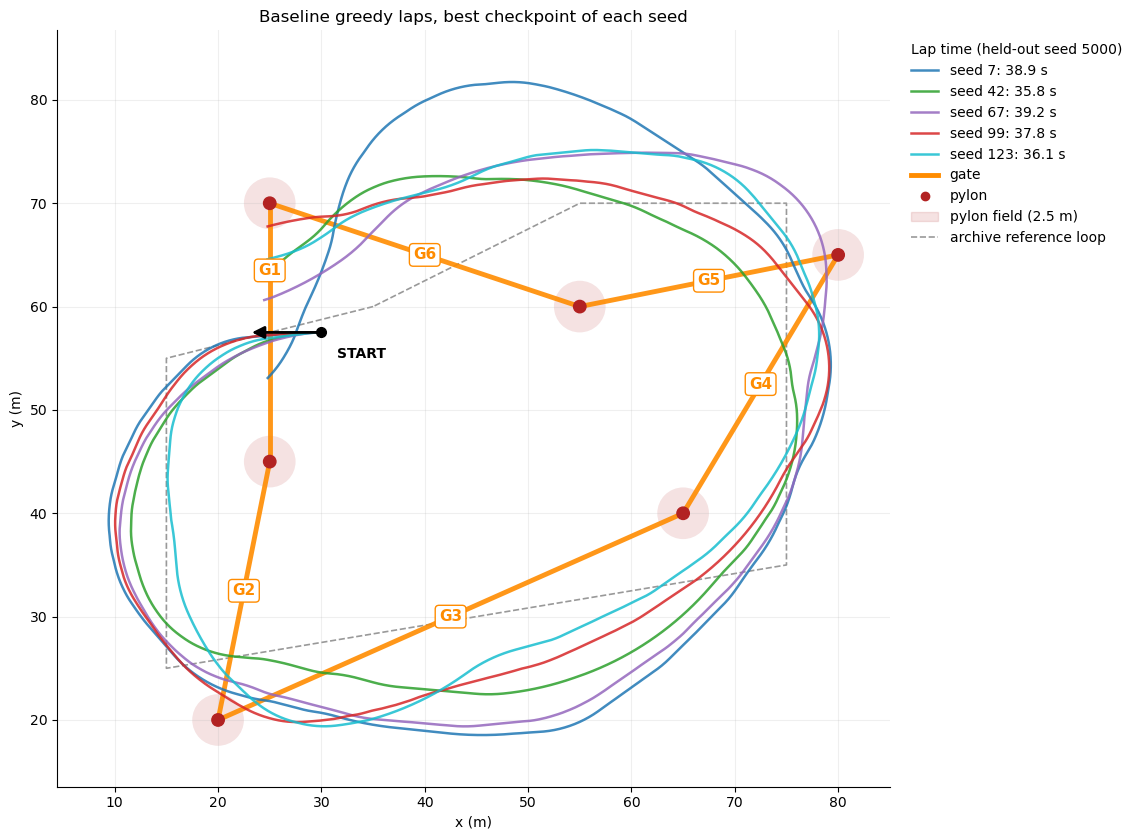

In [5]:
REFERENCE_LINE = np.array([(-10, -5), (-30, -10), (-30, -40), (30, -30), (30, 5), (10, 5), (-10, -5)]) \
    + sweep_2.COURSE_OFFSET
HELD_OUT_SEED = SETTINGS["test_seed_start"]
base = env.unwrapped

fig, ax = plt.subplots(figsize=(11, 8.5))
ax.plot(REFERENCE_LINE[:, 0], REFERENCE_LINE[:, 1], color="0.6", ls="--", lw=1.2, zorder=1)
for pylon in base.PYLONS:
    ax.add_patch(plt.Circle(pylon["xy"], base.PYLON_FIELD_R_M, color="firebrick", alpha=0.13, lw=0, zorder=1))
    ax.add_patch(plt.Circle(pylon["xy"], max(pylon["r"], 0.6), color="firebrick", zorder=5))
for gate in base.GATES:
    ends = np.array([gate["p1"], gate["p2"]])
    ax.plot(ends[:, 0], ends[:, 1], color="darkorange", lw=3.5, solid_capstyle="round", alpha=0.9, zorder=2)
    label_xy = ends.mean(axis=0)
    if np.hypot(label_xy[0] - START["x"], label_xy[1] - START["y"]) < 6:
        far = ends[np.argmax(np.hypot(*(ends - [START["x"], START["y"]]).T))]
        label_xy = label_xy + 6 * (far - label_xy) / np.linalg.norm(far - label_xy)
    ax.text(*label_xy, gate["name"], color="darkorange", fontsize=11, fontweight="bold", ha="center",
            va="center", zorder=6, bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="darkorange", lw=1))

points = [np.array([g[k] for g in base.GATES for k in ("p1", "p2")])]
handles = []
for s in seeds:
    job = next(j for j in jobs if j["seed"] == s)
    run_env, Q = load_q(job, Q_DIR)
    flight = greedy_flight(run_env, Q, HELD_OUT_SEED, record_path=True)
    path = flight["path"]
    points.append(path)
    result = f"{flight['time']:.1f} s" if flight["outcome"] == "lap_finished" else flight["outcome"].replace("_", " ")
    handles += ax.plot(path[:, 0], path[:, 1], color=color_of[s], lw=1.8, alpha=0.85, zorder=3,
                       label=f"seed {s}: {result}")

x0, y0 = START["x"], START["y"]
ax.annotate("", xy=(x0 - 7, y0), xytext=(x0, y0), zorder=7,
            arrowprops=dict(arrowstyle="-|>", color="black", lw=2, mutation_scale=18))
ax.plot(x0, y0, "o", color="black", ms=7, zorder=7)
ax.text(x0 + 1.5, y0 - 2.5, "START", fontsize=10, fontweight="bold", zorder=7)

handles += [Line2D([], [], color="darkorange", lw=3.5, label="gate"),
            Line2D([], [], color="firebrick", marker="o", ls="", ms=6, label="pylon"),
            plt.Circle((0, 0), 1, color="firebrick", alpha=0.13, label=f"pylon field ({base.PYLON_FIELD_R_M:g} m)"),
            Line2D([], [], color="0.6", ls="--", lw=1.2, label="archive reference loop")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False,
          title=f"Lap time (held-out seed {HELD_OUT_SEED})", alignment="left")

lo, hi = np.vstack(points).min(axis=0) - 5, np.vstack(points).max(axis=0) + 5
ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), aspect="equal", xlabel="x (m)", ylabel="y (m)",
       title="Baseline greedy laps, best checkpoint of each seed")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## Saved for later

| File | What | In git |
|---|---|---|
| `results_kinematics.jsonl` | one line per run: lap rate and times, learning curve, `stage_min_d`, reward breakdown, config hash | yes |
| `results_kinematics.config.json` | frozen settings: rewards, physics, START, obs bins, course SHA, training params | yes |
| `baseline_jobs.json` | the 5 jobs (seeds, episodes) | yes |
| `baseline_meta.json` | commit hash, config hash, date, wall time, settings | yes |
| `baseline_summary.csv` | `sweep_2.summarize()` of the baseline runs | yes |
| `q_tables/*.npz` | best-checkpoint Q-table of each run, for flight plots (`sweep_2.load_q`) | no (gitignored) |

Next: the `screen` phase (`python sweep_2.py run screen results_kinematics.jsonl --workers 16 --q-dir q_tables`),
appending to the same results file. Do not change `SETTINGS`, rewards, bins or `START` before then: `run_jobs`
refuses to mix configs, and the baseline would have to be retrained.